***1. Structuring Element***

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

Kernel Rectangular:
 [[1 1 1 ... 1 1 1]
 [1 1 1 ... 1 1 1]
 [1 1 1 ... 1 1 1]
 ...
 [1 1 1 ... 1 1 1]
 [1 1 1 ... 1 1 1]
 [1 1 1 ... 1 1 1]]

Kernel Cross:
 [[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]

Kernel Circle/Ellipse:
 [[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


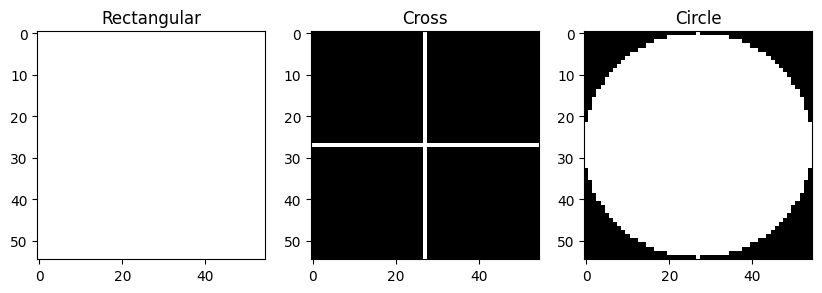

In [68]:
# Définition de la taille de l'élément structurant 
k_size = (55, 55)

# Création des éléments structurants avec OpenCV
kernel_rect = cv2.getStructuringElement(cv2.MORPH_RECT, k_size)
kernel_cross = cv2.getStructuringElement(cv2.MORPH_CROSS, k_size)
kernel_circle = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, k_size)

# Affichage dans la console (Print)
print("Kernel Rectangular:\n", kernel_rect)
print("\nKernel Cross:\n", kernel_cross)
print("\nKernel Circle/Ellipse:\n", kernel_circle)

fig, axes = plt.subplots(1, 3, figsize=(10, 3))

# On force l'échelle : 0=Noir, 1=Blanc
axes[0].imshow(kernel_rect, cmap='gray', vmin=0, vmax=1) 
axes[0].set_title('Rectangular')

axes[1].imshow(kernel_cross, cmap='gray', vmin=0, vmax=1)
axes[1].set_title('Cross')

axes[2].imshow(kernel_circle, cmap='gray', vmin=0, vmax=1)
axes[2].set_title('Circle')

plt.show()

***2. Erosion and Dilatation***

In [8]:
img_smiley = cv2.imread('smiley.png', cv2.IMREAD_GRAYSCALE)

 Image chargée avec succès ! Dimensions : (382, 454)


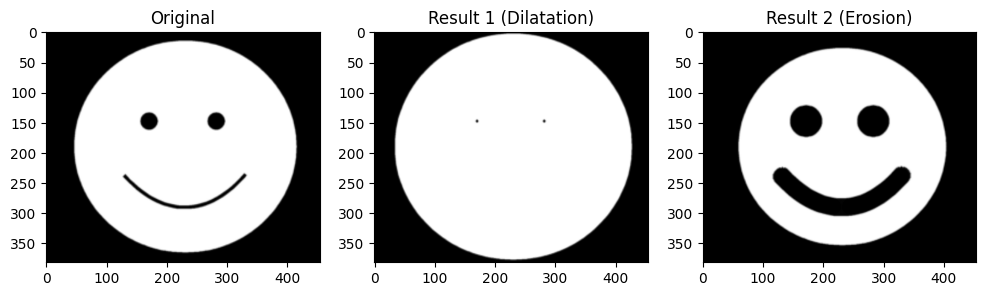

In [77]:
import cv2
import matplotlib.pyplot as plt

path = r"C:\Users\pc\Documents\tp6-image\smiley.png"

img_smiley = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

if img_smiley is None:
    print(f" ERREUR : L'image '{path}' n'a pas pu être chargée.")
    print("Vérifiez que le fichier existe et que le chemin est correct.")
else:
    print(" Image chargée avec succès ! Dimensions :", img_smiley.shape)
    

    es_25 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25))
    result1_cv = cv2.dilate(img_smiley, es_25, iterations=1)
    result2_cv = cv2.erode(img_smiley, es_25, iterations=1)

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(img_smiley, cmap='gray'); axes[0].set_title('Original')
    axes[1].imshow(result1_cv, cmap='gray'); axes[1].set_title('Result 1 (Dilatation)')
    axes[2].imshow(result2_cv, cmap='gray'); axes[2].set_title('Result 2 (Erosion)')
    plt.show()

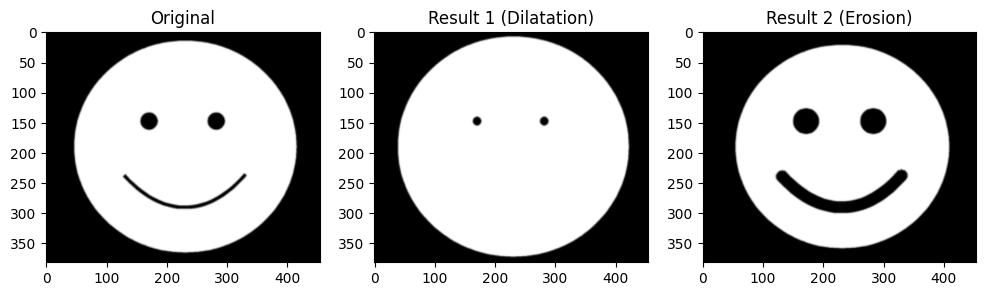

In [79]:
es_25 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))

# Application des fonctions OpenCV
result1_cv = cv2.dilate(img_smiley, es_25, iterations=1)
result2_cv = cv2.erode(img_smiley, es_25, iterations=1)

# Affichage
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(img_smiley, cmap='gray'); axes[0].set_title('Original')
axes[1].imshow(result1_cv, cmap='gray'); axes[1].set_title('Result 1 (Dilatation)')
axes[2].imshow(result2_cv, cmap='gray'); axes[2].set_title('Result 2 (Erosion)')
plt.show()

Calcul de l'érosion manuelle en cours...
Calcul de la dilatation manuelle en cours...


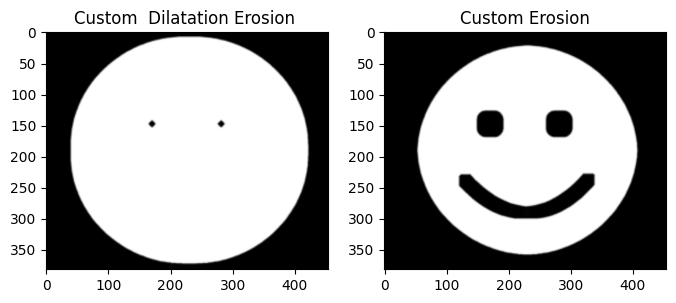

In [81]:

def morpho_convolution(image, ES, yourFunction):
    new_image = np.zeros(image.shape, np.uint8)
    for i in range(0, image.shape[0]):
        for j in range(0, image.shape[1]):
            new_image[i, j] = yourFunction(image, i, j, ES)
    return new_image

# 1. Opérateur d'Érosion (Minimum local)
def my_erode_operator(image, i, j, ES):
    k_h, k_w = ES.shape
    pad_h, pad_w = k_h // 2, k_w // 2
    i_min = max(0, i - pad_h)
    i_max = min(image.shape[0], i + pad_h + 1)
    j_min = max(0, j - pad_w)
    j_max = min(image.shape[1], j + pad_w + 1)
    
    roi = image[i_min:i_max, j_min:j_max]
    
    # L'érosion prend la valeur MINIMALE du voisinage
    return np.min(roi)

# 2. Opérateur de Dilatation (Maximum local)
def my_dilate_operator(image, i, j, ES):
    k_h, k_w = ES.shape
    pad_h, pad_w = k_h // 2, k_w // 2
    
    i_min = max(0, i - pad_h)
    i_max = min(image.shape[0], i + pad_h + 1)
    j_min = max(0, j - pad_w)
    j_max = min(image.shape[1], j + pad_w + 1)
    
    roi = image[i_min:i_max, j_min:j_max]
    
    # La dilatation prend la valeur MAXIMALE du voisinage
    return np.max(roi)

es_test = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))

print("Calcul de l'érosion manuelle en cours...")
custom_eroded = morpho_convolution(img_smiley, es_test, my_erode_operator)

print("Calcul de la dilatation manuelle en cours...")
custom_dilated = morpho_convolution(img_smiley, es_test, my_dilate_operator)

# Affichage des résultats manuels
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(custom_dilated, cmap='gray'); axes[0].set_title('Custom  Dilatation Erosion ')
axes[1].imshow(custom_eroded, cmap='gray'); axes[1].set_title('Custom Erosion')
plt.show()

***3. Contour extraction-based mathematical morphology***

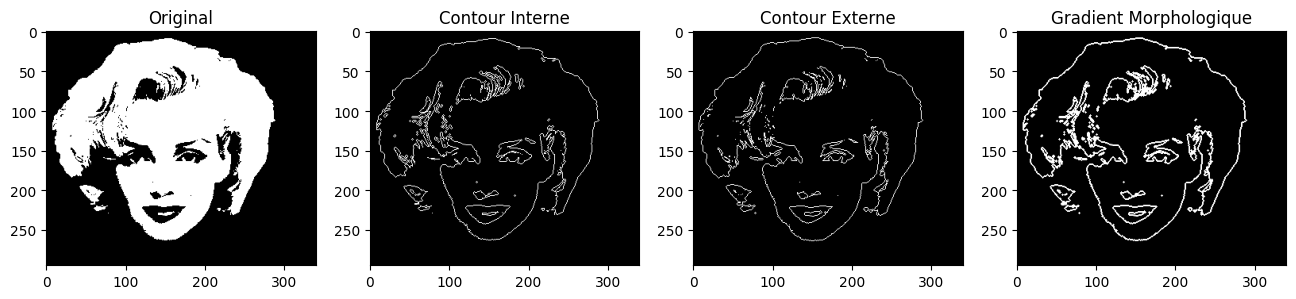

In [48]:
path=r"C:\Users\pc\Documents\tp6-image\mm-binary.png"
img_mm = cv2.imread(path, cv2.IMREAD_GRAYSCALE)


kernel_contour = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))


eroded_mm = cv2.erode(img_mm, kernel_contour, iterations=1)
dilated_mm = cv2.dilate(img_mm, kernel_contour, iterations=1)


contour_interne = cv2.subtract(img_mm, eroded_mm)


contour_externe = cv2.subtract(dilated_mm, img_mm)

# 3. Gradient Morphologique (Contour complet) = Image Dilatée - Image Erodée

gradient_morpho = cv2.subtract(dilated_mm, eroded_mm)


fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(img_mm, cmap='gray'); axes[0].set_title('Original')
axes[1].imshow(contour_interne, cmap='gray'); axes[1].set_title('Contour Interne')
axes[2].imshow(contour_externe, cmap='gray'); axes[2].set_title('Contour Externe')
axes[3].imshow(gradient_morpho, cmap='gray'); axes[3].set_title('Gradient Morphologique')
plt.show()